# WODPredict-AI: detección de fatiga en comentarios de atletas (Actividad 4, versión corregida con la retroalimentación de la docente Tania Mendoza)


Prototipo que compara tres modelos preentrenados de análisis de sentimiento para clasificar los comentarios
que los atletas escriben después de un WOD en **POS** (estado óptimo), **NEU** (sin señal) y **NEG** (fatiga o riesgo).

Cambios respecto a la primera entrega, según la retroalimentación del docente:
- Los tres modelos tienen el mismo espacio de salida nativo de 3 clases.
- El *ground truth* ya no sale de palabras clave: es un conjunto de 84 comentarios validados por un CF-L1/CF-L2 trainer certificado.
- Separación dev/test, métricas por clase, matriz de confusión y recall de NEG como métrica principal.
- Latencia por comentario (mediana de varias corridas), datos cargados desde Hugging Face o el repositorio y código en `src/`.



## Ecosistema Hugging Face

| Componente | Qué es | Cómo se usa en este proyecto |
|---|---|---|
| **Models** (Hub) | Repositorio de modelos preentrenados con su *model card*, pesos y tokenizador | Se descargan los 3 modelos evaluados con `transformers.pipeline` |
| **Datasets** | Repositorio de conjuntos de datos versionados y la librería `datasets` para cargarlos | La exportación de SugarWOD (`rick-lastra/wodpredict-sugarwod-raw`) y el conjunto etiquetado por el coach (`rick-lastra/wodpredict-notas-coach`) se publican como datasets privados y se cargan con `load_dataset`; si no hay acceso, se usan los CSV del repositorio |
| **Spaces** | Hosting de demos conectadas a un modelo del Hub | Despliegue futuro: una demo en Gradio donde el coach pegue un comentario y vea la clase y `prob_fatiga` |
| Librerías | `transformers`, `datasets`, `huggingface_hub`, `evaluate` | Inferencia, carga de datos, autenticación y métricas |

In [3]:
# Punto 1. Configuración de GPU: en Colab, Entorno de ejecución > Cambiar tipo de entorno de ejecución > GPU T4.
import torch

if torch.cuda.is_available():
    DEVICE = 0
    !nvidia-smi
    print("GPU:", torch.cuda.get_device_name(0), "| CUDA", torch.version.cuda)
else:
    DEVICE = -1
    print("Sin GPU: los modelos corren en CPU (en Colab, activa la GPU T4 y reinicia el entorno).")

Wed Oct 14 20:25:57 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 610.43.02              KMD Version: 610.62        CUDA UMD Version: 13.3     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 4050 ...    On  |   00000000:01:00.0  On |                  N/A |
| N/A   43C    P8              4W /  140W |    2068MiB /   6141MiB |     35%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [4]:
# Punto 2. Instalación de dependencias.
# En Colab se clona el repositorio para obtener requirements.txt (las librerías del proyecto), los scripts de src/
# y los CSV de respaldo de data/ (se usan si no hay acceso a los datasets privados de Hugging Face).
# Después se instalan las librerías con pip. En local se usan rutas relativas y el entorno ya instalado.
import os, sys
from pathlib import Path

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    if not Path("WODPredictAI").exists():
        !git clone -q https://github.com/rick-lastra/WODPredictAI.git
    os.chdir("WODPredictAI")
    !pip install -q -r requirements.txt
else:
    # El notebook vive en notebooks/;
    if Path.cwd().name == "notebooks":
        os.chdir("..")

sys.path.insert(0, str(Path("src").resolve()))
Path("resultados").mkdir(exist_ok=True)
print("Directorio de trabajo:", Path.cwd())
# Librerías del proyecto y versión instalada
import re
from importlib.metadata import version, PackageNotFoundError
for linea in Path("requirements.txt").read_text().splitlines():
    paquete = re.split(r"[<>=!~ ]", linea.strip())[0]
    if paquete:
        try:
            print(f"  {paquete:<16} {version(paquete)}")
        except PackageNotFoundError:
            print(f"  {paquete:<16} no instalado")


Directorio de trabajo: /content/WODPredictAI
  torch            2.11.0+cu128
  transformers     5.16.1
  datasets         4.8.5
  huggingface-hub  1.29.0
  sentencepiece    0.2.2
  protobuf         5.29.6
  emoji            2.16.0
  scikit-learn     1.6.1
  pandas           2.2.3
  matplotlib       3.10.0


In [ ]:
# Punto 3. Autenticación en Hugging Face Hub ( para el dataset privado).
# El token en Colab va en Secretos (HF_TOKEN).
import os
from huggingface_hub import login

token = os.environ.get("HF_TOKEN")
if EN_COLAB and not token:
    try:
        from google.colab import userdata
        token = userdata.get("HF_TOKEN")
    except Exception:
        token = None
if token:
    login(token=token, add_to_git_credential=False)
    print("Sesión iniciada en Hugging Face.")
else:
    print("Sin token: los modelos son públicos y el dataset se leerá del repositorio.")

## Datos

Distinción de tres cifras que en la primera entrega se mezclaron:

| Concepto | Cantidad | Archivo |
|---|---|---|
| Filas totales de la exportación de SugarWOD (30/10/2022 a 22/04/2025; una fila por componente del WOD, 248 días entrenados) | 792 | `rick-lastra/wodpredict-sugarwod-raw` o `data/raw/workouts_sugarwod.csv` |
| Entrenamientos con nota (`notes`) | 143 | mismo archivo |
| Muestra experimental etiquetada por el coach | 84 | `rick-lastra/wodpredict-notas-coach` o `data/notas_etiquetadas_coach.csv` |

La celda siguiente muestra por qué hizo falta la muestra etiquetada: casi todas las notas reales son técnicas
(pesos, repeticiones, tiempos) o devocionales, sin percepción de esfuerzo.

In [6]:
# Punto 4. Carga de datasets (1/2): exportación de SugarWOD y filtro de notas técnicas.
import pandas as pd
from datos import cargar_workouts_raw, clasificar_notas


# Origen: huggingface:rick-lastra/wodpredict-sugarwod-raw
pd.set_option("display.max_colwidth", 80)
workouts = cargar_workouts_raw()
notas = clasificar_notas(workouts)
print("Origen:", workouts.attrs["origen"])
print(f"Filas totales: {len(workouts)} | con nota: {len(notas)}")
display(notas["tipo_nota"].value_counts().rename("notas").to_frame())
display(notas[["date", "title", "notes", "tipo_nota"]].sample(8, random_state=1))

Origen: huggingface:rick-lastra/wodpredict-sugarwod-raw
Filas totales: 792 | con nota: 143


,notas
tipo_nota,
tecnica,143


,date,title,notes,tipo_nota
499,2023-11-14,Roy Kent + Jamie Tartt (45-54),DB 45 LB,tecnica
676,2025-01-16,Reading Review,"""Gods Covenant with Abraham""Genesis 15 highlights a pivotal moment where God...",tecnica
183,2023-03-21,Jalapeño (Open),Box HSPU,tecnica
7,2022-12-05,Hunsucker & Malone (Open & QuarterFinals),3 rounds + 32 reps,tecnica
722,2025-01-29,Double Dumbbell Death March + Single Leg Box Squat + Sotts Press,30 lbs DB26.5 lbs Kb,tecnica
247,2023-05-15,Sumo Deadlift 5x10,DB,tecnica
32,2022-12-30,"“The Final Countdown” (Open, QuarterFinals, SemiFinals, & Games)",95 Lb,tecnica
242,2023-05-10,Echo Bike: 200/160 Cal Progression Week 5 Workout 1,4 sets No rest between sets.,tecnica


### Conjunto etiquetado por el CF-L1 trainer (ground truth)
Como se indicó en la retroalimentación se construyó un pequeño conjunto de comentarios etiquetado por coaches en categorías como estado normal, fatiga/recuperación insuficiente y caso ambiguo.

- **Origen:** como las notas reales casi no describen fatiga (y la muestra anterior tenía 0 NEG), se redactaron 84 comentarios
  realistas en español e inglés con el estilo de las notas de un box de CrossFit (normales, de fatiga o dolor y ambiguos).
- **Etiquetado:** Yo, Ricardo Lastra, siendo coach CF-L1, revisé cada comentario y le asigné la etiqueta final (`etiqueta_coach`).
  Cambié 2 de las 84 etiquetas propuestas (concordancia 97.6 %). La columna `etiqueta_propuesta` se conserva solo como trazabilidad.
- **Criterio:** NEG = fatiga, dolor, mala recuperación o riesgo; POS = buena recuperación o desempeño; NEU = logística o sin señal clara.
- **Balance:** 30 NEG, 28 POS y 26 NEU.

In [7]:
# Punto 4. Carga de datasets (2/2): conjunto etiquetado por el coach y split dev/test.
from datos import cargar_etiquetadas, split_dev_test


# Origen: huggingface:rick-lastra/wodpredict-notas-coach
etiquetadas = cargar_etiquetadas()
print("Origen:", etiquetadas.attrs["origen"])
display(pd.crosstab(etiquetadas["etiqueta_coach"], etiquetadas["idioma"], margins=True))

dev, test = split_dev_test(etiquetadas, test_size=0.5, semilla=42)
print(f"dev: {len(dev)} comentarios | test: {len(test)} comentarios")
display(pd.concat({"dev": dev["etiqueta_coach"].value_counts(), "test": test["etiqueta_coach"].value_counts()}, axis=1))

Origen: huggingface:rick-lastra/wodpredict-notas-coach


idioma,en,es,All
etiqueta_coach,,,
NEG,14,16,30
NEU,11,15,26
POS,13,15,28
All,38,46,84


dev: 42 comentarios | test: 42 comentarios


,dev,test
etiqueta_coach,,
NEG,15,15
POS,14,14
NEU,13,13


## Modelos con el mismo espacio de salida (NEG / NEU / POS)

Como se indicó en la retroalimentación de la primera entrega uno de los modelos era binario y no podía reproducir la clase neutral.


| Modelo | Hugging Face | Entrenamiento | Etiquetas nativas |
|---|---|---|---|
| RoBERTuito | `pysentimiento/robertuito-sentiment-analysis` | RoBERTa entrenado con tuits en español (TASS) | NEG, NEU, POS |
| XLM-R Twitter | `cardiffnlp/twitter-xlm-roberta-base-sentiment` | XLM-RoBERTa con ~198 M tuits en 8 idiomas | negative, neutral, positive |
| DistilBERT multilingüe | `lxyuan/distilbert-base-multilingual-cased-sentiments-student` | DistilBERT destilado (zero-shot) en 12 idiomas, el más ligero | negative, neutral, positive |

Se descartan `nlptown/bert-base-multilingual-uncased-sentiment` (1 a 5 estrellas) y `distilbert-base-uncased-finetuned-sst-2-english`
(binario, solo inglés), porque obligaban a inventar un mapeo hacia NEU y la comparación no era justa.
Cada modelo devuelve la probabilidad de las tres clases; `P(NEG)` es la `prob_fatiga` que se integrará al modelo tabular.

In [8]:
# Punto 4. Carga de modelos: los tres modelos se descargan del Hub con transformers.pipeline.
from evaluar import MODELOS, cargar_clasificador

clasificadores = {}
for nombre, ruta in MODELOS.items():
    print(f"Cargando {nombre} ({ruta})...")
    clasificadores[nombre] = cargar_clasificador(ruta, device=DEVICE)
print("Modelos cargados:", ", ".join(clasificadores))

Cargando RoBERTuito (pysentimiento/robertuito-sentiment-analysis)...


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Cargando XLM-R Twitter (cardiffnlp/twitter-xlm-roberta-base-sentiment)...


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Cargando DistilBERT multilingüe (lxyuan/distilbert-base-multilingual-cased-sentiments-student)...


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Modelos cargados: RoBERTuito, XLM-R Twitter, DistilBERT multilingüe


In [9]:
# Punto 5. Pipeline de inferencia: probabilidades NEG / NEU / POS de cada comentario de dev y test.
# Se separan los datos de desarrollo y prueba

from evaluar import predecir_probabilidades

probs_dev, probs_test = {}, {}
for nombre, clf in clasificadores.items():
    probs_dev[nombre] = predecir_probabilidades(clf, dev["texto"].tolist())
    probs_test[nombre] = predecir_probabilidades(clf, test["texto"].tolist())
print("Inferencia completada.")
# Ejemplo: probabilidades de los primeros 3 comentarios de test con el primer modelo
display(probs_test[next(iter(probs_test))].head(3).assign(texto=test["texto"].head(3).tolist()).round(3))

Inferencia completada.


,NEG,NEU,POS,texto
0,0.423,0.497,0.080,"Un poco de molestia en el hombro, pero nada que me impidiera terminar."
1,0.015,0.092,0.894,"Finished Rx with time to spare, very happy."
2,0.069,0.343,0.588,"Hoy volé en el WOD, me sentí muy fuerte en los thrusters."


## Evaluación en test
En la retroalimentación se pide evaluar recall y F1 específicamente para la clase de riesgo. Reportar matriz de confusión y métricas por clase, especialmente recall de NEG.

Métrica principal: **recall de NEG** (no dejar pasar a un atleta fatigado), acompañada de **F1 macro** (las tres clases pesan igual).

=== RoBERTuito (test, argmax) ===
              precision    recall  f1-score   support

         NEG      0.667     0.800     0.727        15
         NEU      0.600     0.462     0.522        13
         POS      0.786     0.786     0.786        14

    accuracy                          0.690        42
   macro avg      0.684     0.682     0.678        42
weighted avg      0.686     0.690     0.683        42

=== XLM-R Twitter (test, argmax) ===
              precision    recall  f1-score   support

         NEG      0.789     1.000     0.882        15
         NEU      0.800     0.308     0.444        13
         POS      0.722     0.929     0.812        14

    accuracy                          0.762        42
   macro avg      0.771     0.745     0.713        42
weighted avg      0.770     0.762     0.724        42

=== DistilBERT multilingüe (test, argmax) ===
              precision    recall  f1-score   support

         NEG      0.733     0.733     0.733        15
         NEU

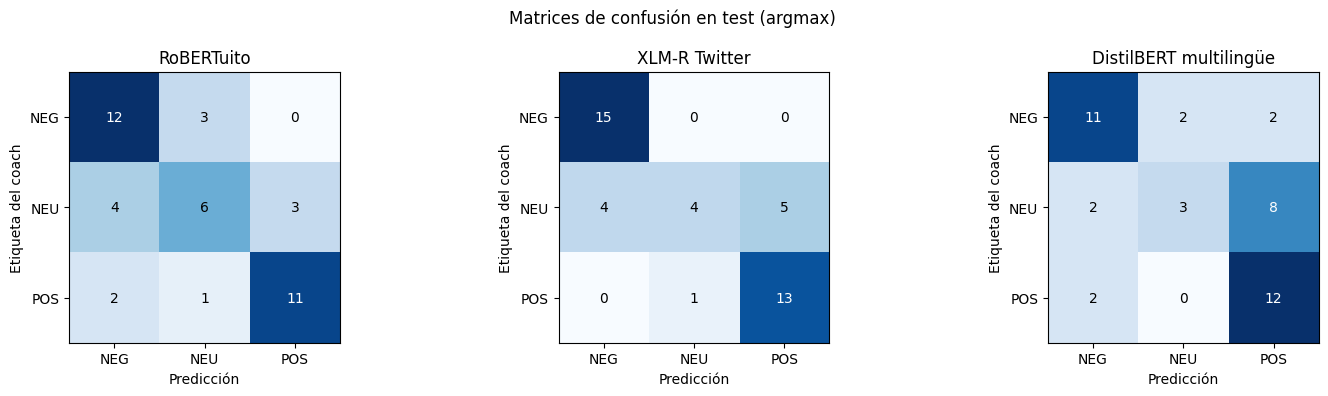

,Accuracy,F1 macro,Precision NEG,Recall NEG,F1 NEG,F1 NEU,F1 POS
Modelo,,,,,,,
RoBERTuito,0.690,0.678,0.667,0.800,0.727,0.522,0.786
XLM-R Twitter,0.762,0.713,0.789,1.000,0.882,0.444,0.812
DistilBERT multilingüe,0.619,0.578,0.733,0.733,0.733,0.333,0.667


In [10]:
# Punto 6. Cálculo de métricas (accuracy, precision, recall, F1-score) y matrices de confusión.
import matplotlib.pyplot as plt
from evaluar import ETIQUETAS, decidir, metricas, reporte, matriz_confusion

y_dev, y_test = dev["etiqueta_coach"].to_numpy(), test["etiqueta_coach"].to_numpy()

filas_argmax = []
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
for eje, nombre in zip(ejes, MODELOS):
    pred = decidir(probs_test[nombre])
    print(f"=== {nombre} (test, argmax) ===")
    print(reporte(y_test, pred))
    filas_argmax.append({"Modelo": nombre, **metricas(y_test, pred)})
    cm = matriz_confusion(y_test, pred)
    eje.imshow(cm.values, cmap="Blues")
    eje.set_xticks(range(3), ETIQUETAS); eje.set_yticks(range(3), ETIQUETAS)
    eje.set_xlabel("Predicción"); eje.set_ylabel("Etiqueta del coach"); eje.set_title(nombre)
    for i in range(3):
        for j in range(3):
            eje.text(j, i, cm.values[i, j], ha="center", va="center",
                     color="white" if cm.values[i, j] > cm.values.max() / 2 else "black")
plt.suptitle("Matrices de confusión en test (argmax)")
plt.tight_layout()
plt.savefig("resultados/matrices_confusion.png", dpi=200, bbox_inches="tight")
plt.show()

tabla_argmax = pd.DataFrame(filas_argmax).set_index("Modelo").round(3)
display(tabla_argmax[["Accuracy", "F1 macro", "Precision NEG", "Recall NEG", "F1 NEG", "F1 NEU", "F1 POS"]])

## Ajuste del umbral de fatiga en dev y reporte en test

Regla: se predice NEG si `P(NEG) >= umbral`; si no, la clase más probable entre NEU y POS.
El umbral de cada modelo se elige **solo con dev** (máximo F1 macro; desempate por recall de NEG) y después se reporta en **test**.

In [11]:
# Métricas con el umbral de P(NEG) elegido en dev, reportadas en test.
from evaluar import elegir_umbral

filas_umbral = []
for nombre in MODELOS:
    umbral = elegir_umbral(y_dev, probs_dev[nombre])
    pred = decidir(probs_test[nombre], umbral)
    filas_umbral.append({"Modelo": nombre, "Umbral P(NEG)": umbral, **metricas(y_test, pred)})
tabla_umbral = pd.DataFrame(filas_umbral).set_index("Modelo").round(3)
display(tabla_umbral[["Umbral P(NEG)", "Accuracy", "F1 macro", "Precision NEG", "Recall NEG", "F1 NEG"]])

,Umbral P(NEG),Accuracy,F1 macro,Precision NEG,Recall NEG,F1 NEG
Modelo,,,,,,
RoBERTuito,0.55,0.667,0.660,0.733,0.733,0.733
XLM-R Twitter,0.45,0.762,0.713,0.789,1.000,0.882
DistilBERT multilingüe,0.40,0.619,0.581,0.786,0.733,0.759


**Conclusión parcial del ajuste:** ajustar el umbral de P(NEG) en dev no cambió el orden de los modelos ni mejoró de forma consistente en test. XLM-R queda igual (umbral 0.45), DistilBERT gana algo de precisión en NEG y RoBERTuito pierde recall de NEG (0.80 a 0.73). Con 42 comentarios en dev el umbral no generaliza, así que se mantiene la regla argmax y se recalibrará cuando haya más datos.

## Latencia  

El requisito de negocio es **< 500 ms por predicción**. Se mide un comentario a la vez (como llegaría desde la API de Wodify),
con 3 inferencias de calentamiento y 5 repeticiones sobre los 42 comentarios de test; se reporta la mediana y el percentil 95.

In [12]:
# Punto 7. Medición de latencia: un comentario a la vez, mediana y p95 de 5 corridas.
from evaluar import medir_latencia

filas_lat = []
for nombre, clf in clasificadores.items():
    filas_lat.append({"Modelo": nombre, **medir_latencia(clf, test["texto"].tolist(), repeticiones=5)})
tabla_latencia = pd.DataFrame(filas_lat).set_index("Modelo").round(1)
dispositivo = "GPU " + torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
print("Dispositivo:", dispositivo)
display(tabla_latencia)

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


Dispositivo: GPU NVIDIA GeForce RTX 4050 Laptop GPU


,Latencia mediana (ms),Latencia p95 (ms),Mediciones
Modelo,,,
RoBERTuito,20.1,31.5,210
XLM-R Twitter,17.8,22.6,210
DistilBERT multilingüe,10.0,13.1,210


,F1 macro,Recall NEG,F1 NEG,Umbral P(NEG) (umbral dev),F1 macro (umbral dev),Recall NEG (umbral dev),Latencia mediana (ms),Latencia p95 (ms),Cumple F1 macro ≥ 0.80,Cumple latencia < 500 ms
Modelo,,,,,,,,,,
RoBERTuito,0.678,0.800,0.727,0.55,0.660,0.733,20.1,31.5,False,True
XLM-R Twitter,0.713,1.000,0.882,0.45,0.713,1.000,17.8,22.6,False,True
DistilBERT multilingüe,0.578,0.733,0.733,0.40,0.581,0.733,10.0,13.1,False,True


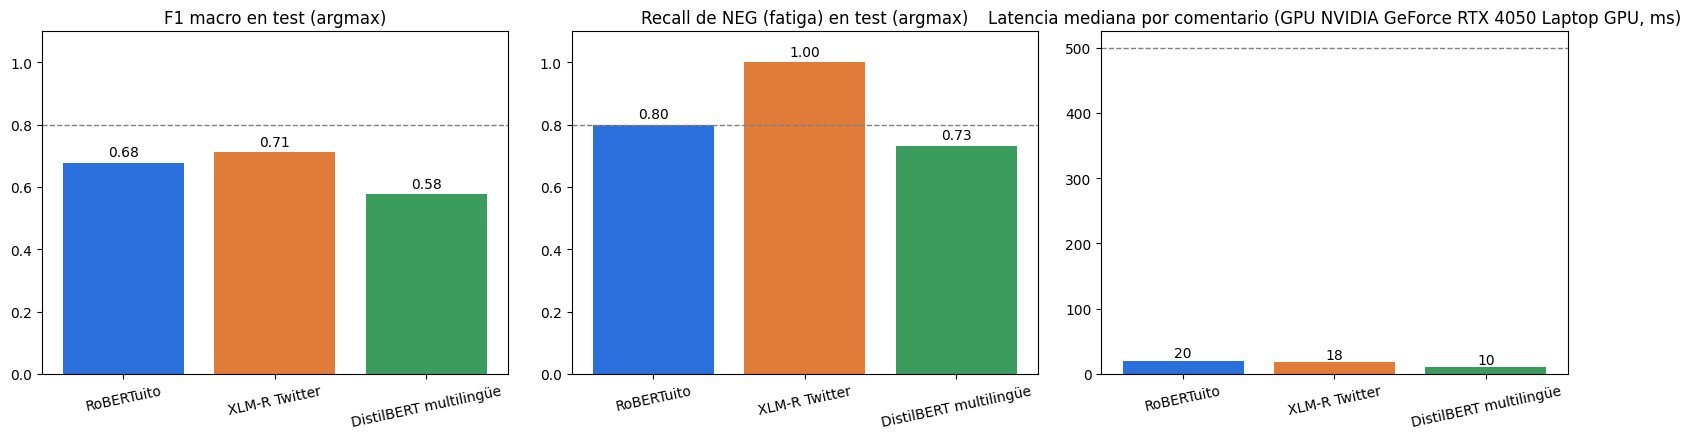

In [13]:
# Punto 8. Tablas o resúmenes: tabla comparativa final y gráficas.

comparativa = tabla_argmax[["F1 macro", "Recall NEG", "F1 NEG"]].join(
    tabla_umbral[["Umbral P(NEG)", "F1 macro", "Recall NEG"]].add_suffix(" (umbral dev)")).join(
    tabla_latencia[["Latencia mediana (ms)", "Latencia p95 (ms)"]])
comparativa["Cumple F1 macro ≥ 0.80"] = comparativa["F1 macro"] >= 0.80
comparativa["Cumple latencia < 500 ms"] = comparativa["Latencia p95 (ms)"] < 500
comparativa.to_csv("resultados/metricas_modelos.csv")
display(comparativa)

colores = ["#2a6fdb", "#e07b39", "#3a9d5d"]
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 4.5))
for eje, columna, titulo in [(ax1, "F1 macro", "F1 macro en test (argmax)"), (ax2, "Recall NEG", "Recall de NEG (fatiga) en test (argmax)")]:
    eje.bar(comparativa.index, comparativa[columna], color=colores)
    eje.axhline(0.80, ls="--", color="gray", lw=1); eje.set_ylim(0, 1.1); eje.set_title(titulo)
    for i, v in enumerate(comparativa[columna]):
        eje.text(i, v + 0.02, f"{v:.2f}", ha="center")
ax3.bar(comparativa.index, comparativa["Latencia mediana (ms)"], color=colores)
ax3.axhline(500, ls="--", color="gray", lw=1); ax3.set_title(f"Latencia mediana por comentario ({dispositivo}, ms)")
for i, v in enumerate(comparativa["Latencia mediana (ms)"]):
    ax3.text(i, v + 5, f"{v:.0f}", ha="center")
for eje in (ax1, ax2, ax3):
    eje.tick_params(axis="x", rotation=12)
plt.tight_layout()
plt.savefig("resultados/comparativa_modelos.png", dpi=200, bbox_inches="tight")
plt.show()

## Punto 9. Conclusiones parciales por modelo

- **RoBERTuito:** recall de NEG 0.80 y F1 macro 0.68 en test. Detecta bien la fatiga en español e inglés, pero confunde los comentarios neutros con NEG o POS (recall de NEU 0.46).
- **XLM-R Twitter:** el mejor del grupo. Detectó los 15 comentarios de fatiga de test (recall de NEG 1.00, precisión de NEG 0.79) y tiene el F1 macro más alto (0.71). Su punto débil es NEU (recall 0.31): manda comentarios neutros a NEG o POS, que en producción serían falsas alarmas que el coach tendría que descartar.
- **DistilBERT multilingüe:** el más rápido (menos de 40 ms de mediana en CPU), pero el menos preciso: F1 macro 0.58, recall de NEG 0.73 y casi no reconoce NEU (recall 0.23). Solo convendría si la latencia fuera la restricción principal.

## Integración con el modelo tabular: `prob_fatiga`

En la retroalimentación se suguiere usar `P(NEG)` del modelo de texto como una característica más del modelo tabular.
La exportación de SugarWOD solo trae `rx_or_scaled`, `pr`, `score_type` y `best_result_raw`; **RPE y ACWR por carga no existen**
en estos datos y quedan como columnas pendientes. Mientras tanto se calcula un proxy de ACWR por frecuencia (días entrenados en
los últimos 7 días entre el promedio semanal de los últimos 28).

Como las 143 notas reales son técnicas, aquí `prob_fatiga` se calcula sobre ellas solo para mostrar el flujo de datos; la tabla
de abajo deja ver por qué en producción hay que filtrar antes las notas técnicas (`solo_subjetivas=True`).

In [14]:
from integrar_tabular import construir_features

MODELO_CANDIDATO = comparativa["F1 macro"].idxmax()
print("Modelo candidato para prob_fatiga:", MODELO_CANDIDATO)
features = construir_features(workouts, clasificadores[MODELO_CANDIDATO])
features.to_csv("resultados/features_tabulares.csv", index=False)
print(f"{len(features)} entrenamientos, {features['prob_fatiga'].notna().sum()} con prob_fatiga")
display(features.dropna(subset=["prob_fatiga"]).sort_values("prob_fatiga", ascending=False).head(8))

Modelo candidato para prob_fatiga: XLM-R Twitter
792 entrenamientos, 143 con prob_fatiga


,date,title,score_type,best_result_raw,es_rx,es_pr,dias_desde_sesion_previa,dias_entrenados_7d,dias_entrenados_28d_prom_semanal,acwr_frecuencia_proxy,rpe,acwr_carga,notes,prob_fatiga
745,2025-02-06,Reading Review,Other / Text,0.0,1,0,1.0,5.0,6.00,0.833333,NaN,NaN,"""Overcoming Excuses""In Exodus 3-4, we encounter Moses making several excuses...",0.496219
460,2023-09-22,Mango Habanero,NaN,900.0,0,0,2.0,4.0,3.50,1.142857,NaN,NaN,Time cap,0.467880
49,2023-01-10,Cream Cheese Danish (Open & QuarterFinals),NaN,945.0,0,0,1.0,4.0,3.25,1.230769,NaN,NaN,Air bike 25 calories instead of running.,0.393723
254,2023-05-22,Hawaii (45-54),NaN,995.0,0,0,6.0,2.0,2.25,0.888889,NaN,NaN,Without Vest,0.379157
291,2023-06-28,Animal Kingdom (45-54),NaN,1020.0,0,0,1.0,4.0,3.00,1.333333,NaN,NaN,TC,0.354047
70,2023-01-30,Good Morning,Load,65.0,0,0,3.0,5.0,3.50,1.428571,NaN,NaN,Rings plank to pike.,0.338846
674,2025-01-15,Tempo Good Morning + Single Leg Box Squat + Sotts Press,Other / Text,0.0,1,0,1.0,7.0,3.50,2.000000,NaN,NaN,45,0.336662
242,2023-05-10,Echo Bike: 200/160 Cal Progression Week 5 Workout 1,NaN,1085.0,0,0,1.0,3.0,2.50,1.200000,NaN,NaN,4 sets No rest between sets.,0.330960


## Conclusiones generales

Ningún modelo alcanza el F1 macro de 0.80 que se fijó como umbral de negocio, así que ninguno está listo para producción. Los tres cumplen con holgura la latencia de < 500 ms por comentario.

Con el *ground truth* del CF-L1 trainer, **XLM-R Twitter** es el mejor candidato: no se le escapó ningún comentario de fatiga en test y su F1 macro (0.71) es el más alto. **RoBERTuito**, el modelo elegido en la primera entrega de la actividad 4, queda como segundo candidato (recall de NEG 0.80, F1 macro 0.68). Su F1 de 0.859 anterior estaba inflado por etiquetas de palabras clave sin casos NEG; con etiquetas de coach y clases balanceadas la diferencia entre modelos es mucho menor.

La clase más difícil para los tres es NEU, lo que se traduce en falsas alarmas. Por eso la salida se usa como señal para el coach (*human-in-the-loop*) y no como diagnóstico. La sección de integración con el modelo tabular muestra además que el modelo asigna P(NEG) alta a notas que no hablan del estado del atleta (por ejemplo, devocionales), lo que confirma que hay que filtrar las notas técnicas antes de usar `prob_fatiga`.

### Limitaciones
- Las etiquetas anteriores eran heurísticas.
- Ahora las 84 notas son redactadas y validadas por un solo coach; falta medir concordancia con un segundo coach y probar con notas reales de atletas.
- Las notas reales de la exportación son en su mayoría técnicas; antes de producción hay que pedir a los atletas un comentario breve de percepción de esfuerzo.

